# Time Service Example Notebook

This notebook uses API-like functions from time_service.py (without creating a real API server).

It demonstrates two endpoint-style calls:
1. Data endpoint: travel-time + category data + ESRI counts
2. Map endpoint: visualization for the same payload

In [20]:
import importlib
import matplotlib.pyplot as plt
import pandas as pd

import time_service
importlib.reload(time_service)

from time_service import endpoint_time_features, endpoint_esri_feature_counts, endpoint_render_map

In [17]:
payload = endpoint_time_features(
    place_query="Plaza de la Virgen, Valencia",
    minutes=40,
    profile="driving-car",
    country_hint="ESP",
    context_fetch_padding_ratio=0.8,
 )

print("Center:", payload["center_name"] )
print("Time (minutes):", payload["minutes"] )
print("Iso source:", payload["iso_source"] )
print("BBox:", payload["bbox"] )
print("Context bbox:", payload["context_bbox"] )

counts = endpoint_esri_feature_counts(payload)
print("\nESRI feature counts by category:")
print(counts)

display(payload["summary"])

Center: Plaça de la Mare de Déu, Ciutat Vella, València, Comarca de València, València / Valencia, Comunitat Valenciana, España
Time (minutes): 40
Iso source: osm_ors_isochrone
BBox: [-0.885608, 39.092492, -0.121483, 39.860459]
Context bbox: [-1.496908, 38.4781184, 0.48981699999999995, 40.4748326]

ESRI feature counts by category:
{'administrative': 6, 'hydrography': 8, 'transport': 8, 'places': 16}


,category,esri_count,earthmapper_count
0,administrative,6,654
1,hydrography,8,14
2,transport,8,21
3,places,16,22


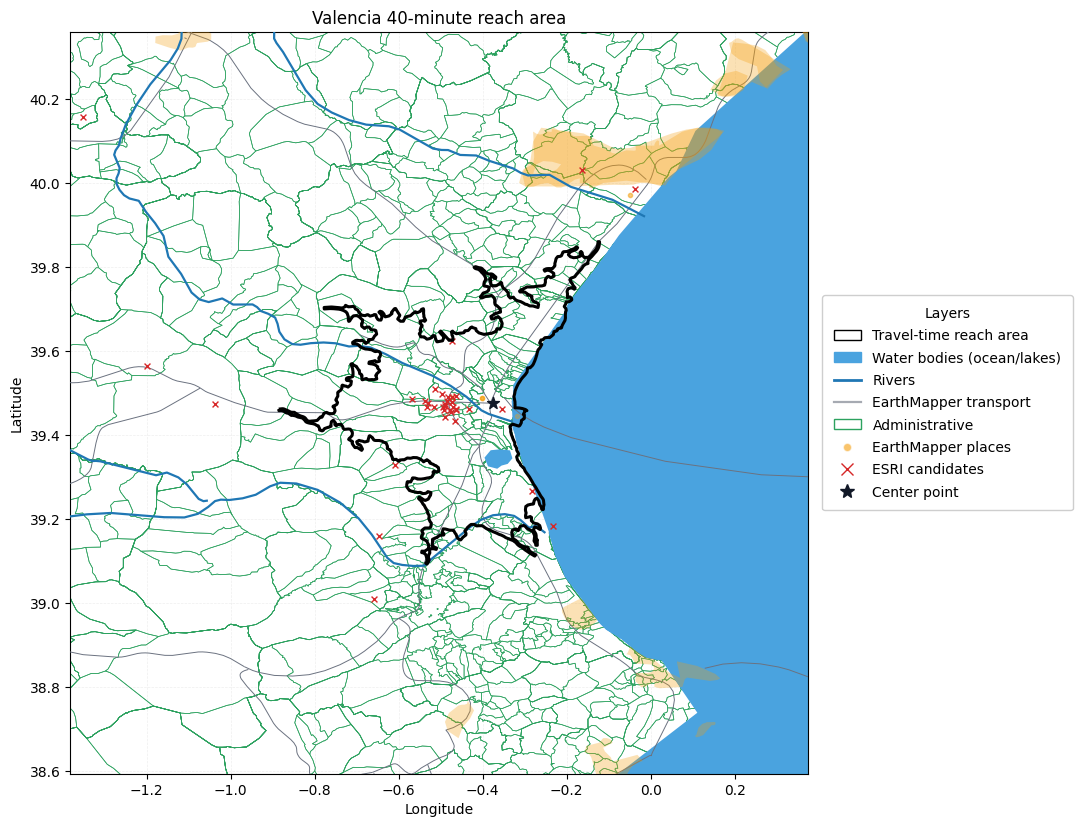

In [21]:
fig = endpoint_render_map(
    payload,
    title="Valencia 40-minute reach area",
    context_padding_ratio=0.65,
 )
plt.show()

Second location center: Plaza Nueva
Second location ESRI counts: {'administrative': 2, 'hydrography': 8, 'transport': 8, 'places': 16}


,category,esri_count,earthmapper_count
0,administrative,2,262
1,hydrography,8,12
2,transport,8,22
3,places,16,19


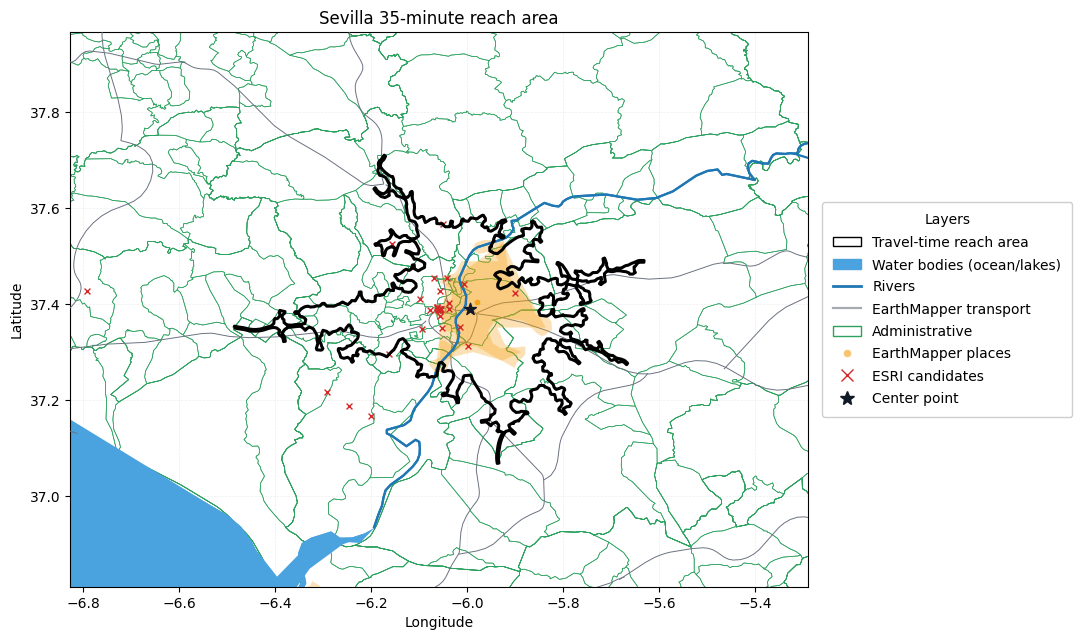

In [22]:
payload2 = endpoint_time_features(
    place_query="Plaza Nueva, Sevilla",
    minutes=35,
    profile="driving-car",
    country_hint="ESP",
)

print("Second location center:", payload2["center_name"])
print("Second location ESRI counts:", endpoint_esri_feature_counts(payload2))
display(payload2["summary"])

fig2 = endpoint_render_map(payload2, title="Sevilla 35-minute reach area")
plt.show()

Second location center: Statue of Liberty
Second location ESRI counts: {'administrative': 10, 'hydrography': 8, 'transport': 16, 'places': 16}


,category,esri_count,earthmapper_count
0,administrative,10,66
1,hydrography,8,32
2,transport,16,382
3,places,16,91


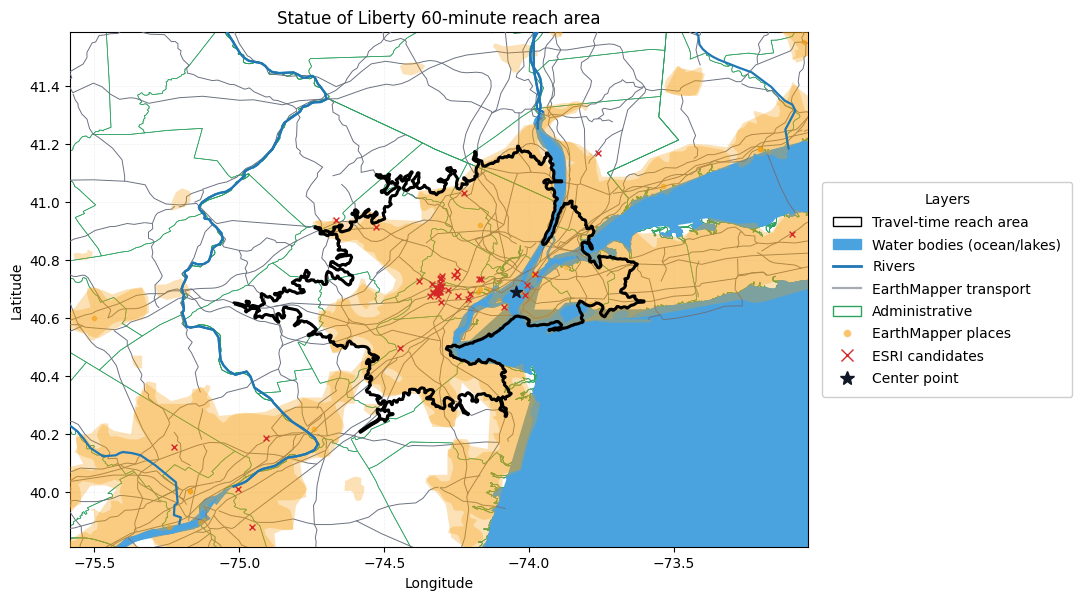

In [23]:
payload3 = endpoint_time_features(
    place_query="Statue of Liberty",
    minutes=60,
    profile="driving-car",
    country_hint="USA",
)

print("Second location center:", payload3["center_name"])
print("Second location ESRI counts:", endpoint_esri_feature_counts(payload3))
display(payload3["summary"])

fig2 = endpoint_render_map(payload3, title="Statue of Liberty 60-minute reach area")
plt.show()